# Our Goal



### 1. Data cleaning

### 2. EDA

### 3. Text Preprocessing

### 4. Model building

### 5. Evaluation

### 6. Improvement

### 7. Website

### 8. Deploy

In [ ]:
!pip install kagglehub

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("uciml/sms-spam-collection-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'sms-spam-collection-dataset' dataset.
Path to dataset files: /kaggle/input/sms-spam-collection-dataset


In [ ]:
import pandas as pd
import os

df = pd.read_csv(
    os.path.join(path, "spam.csv"),
    encoding="latin-1"   # important for this file
)

df.head()

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN


In [ ]:
df.shape

(5572, 5)

# Data Cleaning

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB


In [ ]:
# dropping the last 3 columns due to they are not good

df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], inplace=True)

In [ ]:
df.head()

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


In [ ]:
# v1, v2 is basic name which do not define the columns name so we rename it
df.rename(columns={'v1': 'target', 'v2': 'text'}, inplace=True)
df.sample(5) # sample show any n randoms rows

,target,text
2307,spam,WIN a year supply of CDs 4 a store of ur choic...
1699,ham,Ok...
3996,spam,Bored housewives! Chat n date now! 0871750.77....
1050,ham,Are you available for soiree on June 3rd?
2716,ham,"House-Maid is the murderer, coz the man was mu..."


### the target has has the ham and spam, so we use the label encoding(due to they are two value, so no need of the one-hot encoding) {encoding means changing the text to the binary so machine can undestand it}

In [ ]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [ ]:
df['target'] = encoder.fit_transform(df['target'])

In [ ]:
df.sample(5) # ham for 0 and spam for  1

,target,text
2540,0,"They said if its gonna snow, it will start aro..."
3784,0,Let me know if you need anything else. Salad o...
951,0,Shb b ok lor... Thanx...
2044,0,I can send you a pic if you like :)
4165,0,Well if I'm that desperate I'll just call arma...


In [ ]:
# checking for the null value

df.isnull().sum() # there is no null value

,0
target,0
text,0


In [ ]:
# checking for the duplicate value(total number of the duplicate values)
df.duplicated().sum()

np.int64(403)

In [ ]:
df = df.drop_duplicates(keep='first') # keep ='first' only keep first remove the other which is duplicate
# {in this duplicacy removal the whole row get removed}

In [ ]:
df.duplicated().sum()

np.int64(0)

# EDA

### it helps to get the data knowledge by performing the differnts operations


##### The main purpose of the EDA, understand the data before applying the ML

In [ ]:
# counting the no of ham ans spam

values = df['target'].value_counts()
print(values)

target
0    4516
1     653
Name: count, dtype: int64


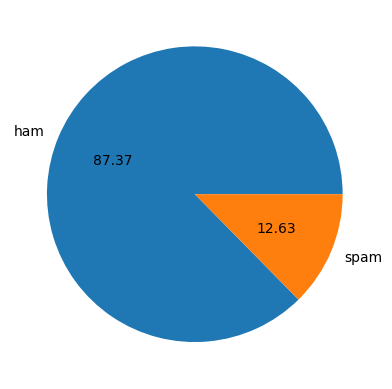

In [ ]:
import matplotlib.pyplot as plt
plt.pie(values, labels=['ham', 'spam'], autopct='%0.2f')
plt.show()

### The next EDA in which we see how much the words, sentences and apl

In [ ]:
!pip install nltk
import nltk

NLTK (Natural Language Toolkit) ek Python library hai jo human language (text) ko process, analyze aur understand karne ke kaam aati hai.


In [ ]:
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# charcter se cheer chaar


df['text'].apply(len) # finding the length in the each of the rows of the text columns

,text
0,111
1,29
2,155
3,49
4,61
...,...
5567,161
5568,37
5569,57
5570,125


In [ ]:
# adding a new rows of the nums character
df['nums_character'] = df['text'].apply(len)
df.head()

,target,text,nums_character
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


- apply(...)

	•	apply() ek function ko har row par apply karta hai
	•	Matlab: har SMS message par kaam karega

---

- lambda x:

	•	lambda = small anonymous function
	•	x = ek SMS message (string)


In [ ]:
# Example

x = "Free entry in a weekly competition"
nltk.word_tokenize(x)

['Free', 'entry', 'in', 'a', 'weekly', 'competition']

The main purpose of the doing this
-  kii ys se word count nikalta haiye
-  Text preprocessing( Stopwords removal, Stemming, Vectorization (BoW / TF-IDF)) and others

In [ ]:
# word se cheer chaar

# Ye line text column ke har message ko words (tokens) mein tod deti hai.

df['text'].apply(lambda x:nltk.word_tokenize(x))

,text
0,"[Go, until, jurong, point, ,, crazy, .., Avail..."
1,"[Ok, lar, ..., Joking, wif, u, oni, ...]"
2,"[Free, entry, in, 2, a, wkly, comp, to, win, F..."
3,"[U, dun, say, so, early, hor, ..., U, c, alrea..."
4,"[Nah, I, do, n't, think, he, goes, to, usf, ,,..."
...,...
5567,"[This, is, the, 2nd, time, we, have, tried, 2,..."
5568,"[Will, Ì_, b, going, to, esplanade, fr, home, ?]"
5569,"[Pity, ,, *, was, in, mood, for, that, ., So, ..."
5570,"[The, guy, did, some, bitching, but, I, acted,..."


In [ ]:
# adding another columns that is nums_words
df['nums_words']= df['text'].apply(lambda x: len(nltk.word_tokenize(x)))
df.head()

,target,text,nums_character,nums_words
0,0,"Go until jurong point, crazy.. Available only ...",111,24
1,0,Ok lar... Joking wif u oni...,29,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37
3,0,U dun say so early hor... U c already then say...,49,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15


In [ ]:
# no of the sentences
df['text'].apply(lambda x:nltk.sent_tokenize(x))

,text
0,"[Go until jurong point, crazy.., Available onl..."
1,"[Ok lar..., Joking wif u oni...]"
2,[Free entry in 2 a wkly comp to win FA Cup fin...
3,[U dun say so early hor... U c already then sa...
4,"[Nah I don't think he goes to usf, he lives ar..."
...,...
5567,[This is the 2nd time we have tried 2 contact ...
5568,[Will Ì_ b going to esplanade fr home?]
5569,"[Pity, * was in mood for that., So...any other..."
5570,[The guy did some bitching but I acted like i'...


In [ ]:
# adding the columns of the no of the sentences

df['nums_sentence']= df['text'].apply(lambda x: len(nltk.sent_tokenize(x)))
df.head()

,target,text,nums_character,nums_words,nums_sentence
0,0,"Go until jurong point, crazy.. Available only ...",111,24,2
1,0,Ok lar... Joking wif u oni...,29,8,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,37,2
3,0,U dun say so early hor... U c already then say...,49,13,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,15,1


In [ ]:
df[['nums_character', 'nums_words', 'nums_sentence' ]].describe()

# descriibe about the overall per sms things

,nums_character,nums_words,nums_sentence
count,5169.000000,5169.000000,5169.000000
mean,78.977945,18.455794,1.965564
std,58.236293,13.324758,1.448541
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [ ]:
# ham(about the ham)

df[df['target'] ==0][['nums_character', 'nums_words', 'nums_sentence' ]].describe()

,nums_character,nums_words,nums_sentence
count,4516.000000,4516.000000,4516.000000
mean,70.459256,17.123782,1.820195
std,56.358207,13.493970,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [ ]:
# spam (about the spam)

df[df['target'] ==1][['nums_character', 'nums_words', 'nums_sentence' ]].describe()

,nums_character,nums_words,nums_sentence
count,653.000000,653.000000,653.000000
mean,137.891271,27.667688,2.970904
std,30.137753,7.008418,1.488425
min,13.000000,2.000000,1.000000
25%,132.000000,25.000000,2.000000
50%,149.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,224.000000,46.000000,9.000000


In [ ]:
# plot the histo

!pip install seaborn

import seaborn as sns

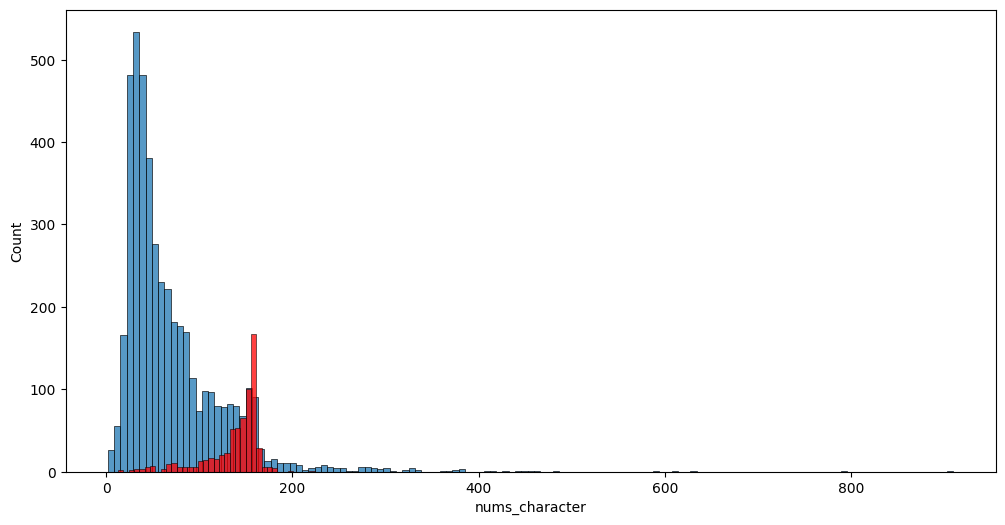

In [ ]:
# histo plot on the basic of the nums_character

plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] ==0]['nums_character'])
sns.histplot(df[df['target'] ==1]['nums_character'], color='red')
plt.show()


### For see the relatioinship between the this columns we use the pairplot

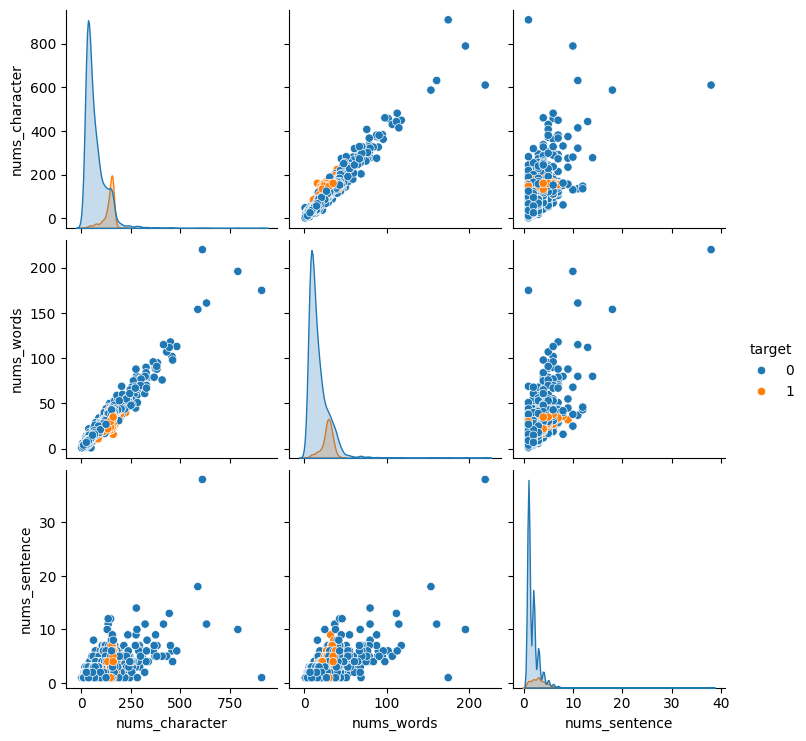

In [ ]:
sns.pairplot(df, hue='target')
plt.show()

#3. Data Preprocessing
• Lower case

• Tokenization

• Removing special characters

• Removing stop word and punctuation

• Stemming

In [ ]:
## what are the stop word : Stop words are common words that usually do not add important meaning to a sentence.

# Eg: is, am, are, the, a, an, in, on, for, and, but

# below are the stop words
nltk.download('stopwords')

from nltk.corpus import stopwords
stopwords.words('english')


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been',
 'before',
 'being',
 'below',
 'between',
 'both',
 'but',
 'by',
 'can',
 'couldn',
 "couldn't",
 'd',
 'did',
 'didn',
 "didn't",
 'do',
 'does',
 'doesn',
 "doesn't",
 'doing',
 'don',
 "don't",
 'down',
 'during',
 'each',
 'few',
 'for',
 'from',
 'further',
 'had',
 'hadn',
 "hadn't",
 'has',
 'hasn',
 "hasn't",
 'have',
 'haven',
 "haven't",
 'having',
 'he',
 "he'd",
 "he'll",
 'her',
 'here',
 'hers',
 'herself',
 "he's",
 'him',
 'himself',
 'his',
 'how',
 'i',
 "i'd",
 'if',
 "i'll",
 "i'm",
 'in',
 'into',
 'is',
 'isn',
 "isn't",
 'it',
 "it'd",
 "it'll",
 "it's",
 'its',
 'itself',
 "i've",
 'just',
 'll',
 'm',
 'ma',
 'me',
 'mightn',
 "mightn't",
 'more',
 'most',
 'mustn',
 "mustn't",
 'my',
 'myself',
 'needn',
 "needn't",
 'no',
 'nor',
 'not',
 'now',
 'o',
 'of',
 'off',
 'on',
 'once',
 'on

In [ ]:
# what are the punctation

import string
string.punctuation

'!"#$%&\'()*+,-./:;<=>?@[\\]^_`{|}~'

In [ ]:
# what is the stemming
# Stemming means reducing a word to its root (base) form by removing prefixes or suffixes.

from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
ps.stem('loving')

'love'

#### a function is made which is perfer data preprocessing

In [ ]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()  # Porter Stemmer object for stemming words

def transform_text(text):

    # 1️⃣ Convert entire text to lowercase
    # Purpose: "Free" and "free" should be treated as same word
    text = text.lower()

    # 2️⃣ Tokenize the text
    # Purpose: Split sentence into individual words (tokens)
    text = nltk.word_tokenize(text)

    y = []  # temporary list to store cleaned tokens

    # 3️⃣ Remove special characters
    # Keep only alphanumeric words (letters + numbers)
    for word in text:
        if word.isalnum():
            y.append(word)

    # Copy cleaned tokens back to text
    text = y[:]     # cloning list (avoid reference issue)
    y.clear()       # clear temp list for reuse

    # 4️⃣ Remove stopwords and punctuation
    # Purpose: Remove common words like 'is', 'the', 'and'
    for word in text:
        if word not in stopwords.words('english') and word not in string.punctuation:
            y.append(word)

    # Copy filtered words back to text
    text = y[:]
    y.clear()

    # 5️⃣ Stemming
    # Reduce words to their root form
    # Example: playing → play, studying → studi
    for word in text:
        y.append(ps.stem(word))

    # 6️⃣ Join processed words back into a sentence
    return " ".join(y)

In [ ]:
# Example: what can transform_text function can do?
a = 'I loved the YT legtures on Machine Learning. How about you?'
transform_text(a)

'love yt legtur machin learn'

In [ ]:
# Example of the one rows of the dataset
transform_text(df['text'][10])

'gon na home soon want talk stuff anymor tonight k cri enough today'

### adding one columns which is name as transfomed text with apply the function that is transform_text

In [ ]:
df['transformed_text'] = df['text'].apply(transform_text)

In [ ]:
df.sample(5)

,target,text,nums_character,nums_words,nums_sentence,transformed_text
4693,0,Pls give her the food preferably pap very slow...,147,34,4,pl give food prefer pap slowli load sugar take...
1236,0,How much are we getting?,24,6,1,much get
1785,0,I dun believe u. I thk u told him.,34,10,1,dun believ thk u told
4168,0,Haven't heard anything and he's not answering ...,111,24,2,heard anyth answer text guess flake said jb fa...
2807,0,Yes princess! I want to catch you with my big ...,61,14,2,ye princess want catch big strong hand


## WordCloud ek visual representation hota hai jisme text ke words dikhte hain, aur jo word jitni baar aata hai, utna hi bada size mein dikhai deta hai.




In [ ]:
!pip install wordcloud

In [ ]:
from wordcloud import WordCloud
wc = WordCloud(width= 500, height=500, min_font_size=10, background_color='white')

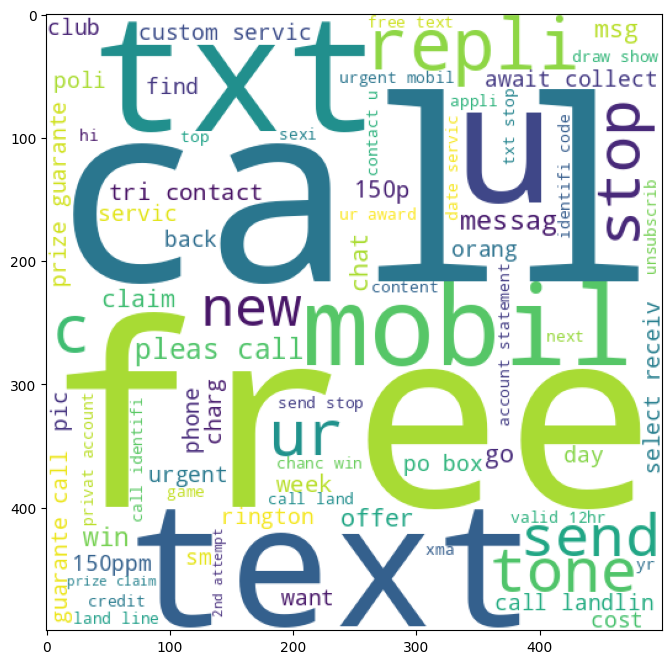

In [ ]:
# spam
spam_wc = wc.generate(df[df['target'] == 1]['transformed_text'].str.cat(sep=' '))
plt.figure(figsize=(12,8))
plt.imshow(spam_wc)
plt.show()

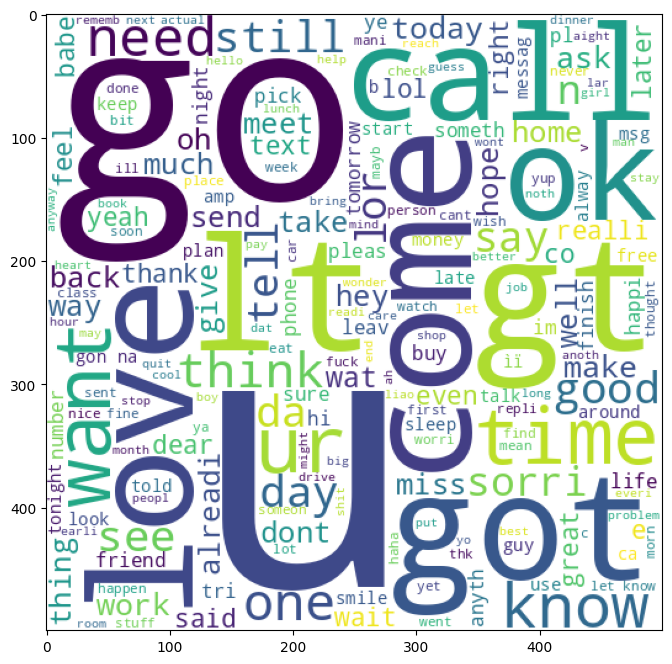

In [ ]:
# ham

spam_wc = wc.generate(df[df['target'] == 0]['transformed_text'].str.cat(sep=' '))
plt.figure(figsize=(12,8))
plt.imshow(spam_wc)
plt.show()

# Ques1: show the most top common word 30

In [ ]:
df[df['target'] == 1]['transformed_text'].tolist()
# converting the ham's transformed_text columns into to the list

['free entri 2 wkli comp win fa cup final tkt 21st may text fa 87121 receiv entri question std txt rate c appli 08452810075over18',
 'freemsg hey darl 3 week word back like fun still tb ok xxx std chg send rcv',
 'winner valu network custom select receivea prize reward claim call claim code kl341 valid 12 hour',
 'mobil 11 month u r entitl updat latest colour mobil camera free call mobil updat co free 08002986030',
 'six chanc win cash 100 pound txt csh11 send cost 6day tsandc appli repli hl 4 info',
 'urgent 1 week free membership prize jackpot txt word claim 81010 c lccltd pobox 4403ldnw1a7rw18',
 'xxxmobilemovieclub use credit click wap link next txt messag click http',
 'england v macedonia dont miss news txt ur nation team 87077 eg england 87077 tri wale scotland poboxox36504w45wq',
 'thank subscript rington uk mobil charg pleas confirm repli ye repli charg',
 '07732584351 rodger burn msg tri call repli sm free nokia mobil free camcord pleas call 08000930705 deliveri tomorrow',
 '

In [ ]:
a = df[df['target'] == 1]['transformed_text'].tolist()

spam_msg = []

for msg in a:
  for word in msg.split():
    spam_msg.append(word)

len(spam_msg)

9939

In [ ]:
from collections import Counter
Counter(spam_msg).most_common(30)

[('call', 320),
 ('free', 191),
 ('2', 155),
 ('txt', 141),
 ('text', 122),
 ('u', 119),
 ('ur', 119),
 ('mobil', 114),
 ('stop', 104),
 ('repli', 103),
 ('claim', 98),
 ('4', 97),
 ('prize', 82),
 ('get', 74),
 ('new', 64),
 ('servic', 64),
 ('tone', 63),
 ('send', 60),
 ('urgent', 57),
 ('nokia', 57),
 ('contact', 56),
 ('award', 55),
 ('phone', 52),
 ('cash', 51),
 ('pleas', 51),
 ('week', 49),
 ('win', 48),
 ('c', 45),
 ('collect', 45),
 ('min', 45)]

          0    1
0      call  320
1      free  191
2         2  155
3       txt  141
4      text  122
5         u  119
6        ur  119
7     mobil  114
8      stop  104
9     repli  103
10    claim   98
11        4   97
12    prize   82
13      get   74
14      new   64
15   servic   64
16     tone   63
17     send   60
18   urgent   57
19    nokia   57
20  contact   56
21    award   55
22    phone   52
23     cash   51
24    pleas   51
25     week   49
26      win   48
27        c   45
28  collect   45
29      min   45


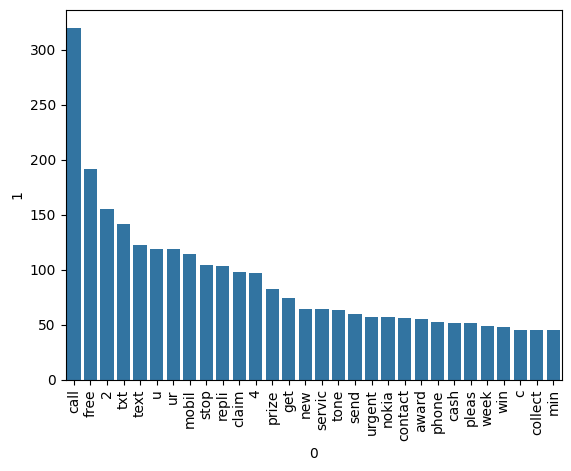

In [ ]:
# showing in the bar plot
data = pd.DataFrame(Counter(spam_msg).most_common(30))
print(data)

sns.barplot(data, x= data[0],y= data[1]) # this is y shown which is unable to read so we rotate it

plt.xticks(rotation='vertical') # comments this out and see the result then uncomments it and see the result you know why have do rotation
plt.show()

# Model Building

### for the model building we have x and y be in the numerical data, but the text columns in text so we convert in the text using the vector using the bag of words(Bag of Words converts text into numbers by counting how many times each word appears. It's Ignores grammar, Ignores word order, Keeps only word frequency)

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()

In [ ]:
X = cv.fit_transform(df['transformed_text']).toarray()

In [ ]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]])

In [ ]:
y = df['target'].values

In [ ]:
y

array([0, 0, 1, ..., 0, 0, 0])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score

In [ ]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [ ]:
gnb.fit(X_train, y_train)

y_pred1 = gnb.predict(X_test)

print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1))

0.8684719535783365
[[772 117]
 [ 19 126]]
0.5185185185185185


In [ ]:
mnb.fit(X_train, y_train)

y_pred2 = mnb.predict(X_test)

print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2))

0.9738878143133463
[[872  17]
 [ 10 135]]
0.8881578947368421


In [ ]:
bnb.fit(X_train, y_train)

y_pred3 = bnb.predict(X_test)

print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3))

0.9661508704061895
[[885   4]
 [ 31 114]]
0.9661016949152542


---------------------------or------------------

we can vector using the tfidfVectorier

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

idf = TfidfVectorizer()

In [ ]:
X = idf.fit_transform(df['transformed_text']).toarray()

In [ ]:
X

array([[0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       ...,
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.],
       [0., 0., 0., ..., 0., 0., 0.]])

In [ ]:
y = df['target'].values

In [ ]:
y

array([0, 0, 1, ..., 0, 0, 0])

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [ ]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score

In [ ]:
gnb = GaussianNB()
mnb = MultinomialNB()
bnb = BernoulliNB()

In [ ]:
gnb.fit(X_train, y_train)

y_pred1 = gnb.predict(X_test)

print(accuracy_score(y_test, y_pred1))
print(confusion_matrix(y_test, y_pred1))
print(precision_score(y_test, y_pred1))

0.8636363636363636
[[772 117]
 [ 24 121]]
0.5084033613445378


In [ ]:
mnb.fit(X_train, y_train)

y_pred2 = mnb.predict(X_test)

print(accuracy_score(y_test, y_pred2))
print(confusion_matrix(y_test, y_pred2))
print(precision_score(y_test, y_pred2))

0.9613152804642167
[[888   1]
 [ 39 106]]
0.9906542056074766


In [ ]:
bnb.fit(X_train, y_train)

y_pred3 = bnb.predict(X_test)

print(accuracy_score(y_test, y_pred3))
print(confusion_matrix(y_test, y_pred3))
print(precision_score(y_test, y_pred3))

0.9661508704061895
[[885   4]
 [ 31 114]]
0.9661016949152542


## we take mnb using the idf because it more the precision (data is inbalanced so precision matter more)

# comparing with other models

In [ ]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    BaggingClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)
from xgboost import XGBClassifier

# ✅ Corrected instantiations
svc = SVC(kernel='sigmoid', gamma=1.0)   # removed space in 'sigmoid'
knc = KNeighborsClassifier()
mnb = MultinomialNB()
dtc = DecisionTreeClassifier(max_depth=5)
lrc = LogisticRegression(solver='liblinear', penalty='l1')  # fixed variable name & penalty
rfc = RandomForestClassifier(n_estimators=50, random_state=2)
abc = AdaBoostClassifier(n_estimators=50, random_state=2)
bc = BaggingClassifier(n_estimators=50, random_state=2)
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)
gbdt = GradientBoostingClassifier(n_estimators=50, random_state=2)
xgb = XGBClassifier(n_estimators=50, random_state=2)

In [ ]:
clfs = {
    'SVC': svc,          # instance of SVC
    'KN': knc,           # KNeighborsClassifier
    'NB': mnb,           # MultinomialNB
    'DT': dtc,           # DecisionTreeClassifier
    'LR': lrc,           # LogisticRegression
    'RF': rfc,           # RandomForestClassifier
    'AdaBoost': abc,     # AdaBoostClassifier
    'BgC': bc,           # BaggingClassifier
    'ETC': etc,          # ExtraTreesClassifier
    'GBDT': gbdt,        # GradientBoostingClassifier
    'xgb': xgb           # XGBClassifier
}

In [ ]:
from sklearn.metrics import accuracy_score, precision_score

def train_classifier(clf, X_train, y_train, X_test, y_test):
    # Fit the model
    clf.fit(X_train, y_train)

    # Predict on test set
    y_pred = clf.predict(X_test)

    # Evaluate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted')  # handles multiclass

    return accuracy, precision

In [ ]:
train_classifier(svc, X_train, y_train, X_test, y_test)

(0.971953578336557, 0.9714843152475836)

In [ ]:
accuracy_scores = []
precision_scores = []

for name,clf in clfs.items():

    current_accuracy,current_precision = train_classifier(clf, X_train,y_train,X_test,y_test)

    print("For ",name)
    print("Accuracy - ",current_accuracy)
    print("Precision - ",current_precision)

    accuracy_scores.append(current_accuracy)
    precision_scores.append(current_precision)

For  SVC
Accuracy -  0.971953578336557
Precision -  0.9714843152475836
For  KN
Accuracy -  0.8965183752417795
Precision -  0.9076353770983353
For  NB
Accuracy -  0.9613152804642167
Precision -  0.9625179548498087
For  DT
Accuracy -  0.9342359767891683
Precision -  0.931458507552883
For  LR
Accuracy -  0.9439071566731141
Precision -  0.9416805070634653
For  RF
Accuracy -  0.9700193423597679
Precision -  0.9706941125902327
For  AdaBoost
Accuracy -  0.9148936170212766
Precision -  0.9086447591169402
For  BgC
Accuracy -  0.9613152804642167
Precision -  0.9607547166291042
For  ETC
Accuracy -  0.9738878143133463
Precision -  0.9743741067737761
For  GBDT
Accuracy -  0.9506769825918762
Precision -  0.9507319179333592
For  xgb
Accuracy -  0.9748549323017408
Precision -  0.9746142317983292


In [ ]:
performance_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy':accuracy_scores,'Precision':precision_scores}).sort_values('Precision',ascending=False)
performance_df

,Algorithm,Accuracy,Precision
10,xgb,0.974855,0.974614
8,ETC,0.973888,0.974374
0,SVC,0.971954,0.971484
5,RF,0.970019,0.970694
2,NB,0.961315,0.962518
7,BgC,0.961315,0.960755
9,GBDT,0.950677,0.950732
4,LR,0.943907,0.941681
3,DT,0.934236,0.931459
6,AdaBoost,0.914894,0.908645


# model improvement

In [ ]:
# 1. Change the max_features parameter of TfIdf
temp_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy_max_ft_3000':accuracy_scores,'Precision_max_ft_3000':precision_scores}).sort_values('Precision_max_ft_3000',ascending=False)
temp_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy_scaling':accuracy_scores,'Precision_scaling':precision_scores}).sort_values('Precision_scaling',ascending=False)
new_df = performance_df.merge(temp_df,on='Algorithm')
new_df_scaled = new_df.merge(temp_df,on='Algorithm')
temp_df = pd.DataFrame({'Algorithm':clfs.keys(),'Accuracy_num_chars':accuracy_scores,'Precision_num_chars':precision_scores}).sort_values('Precision_num_chars',ascending=False)
new_df_scaled.merge(temp_df,on='Algorithm')

,Algorithm,Accuracy,Precision,Accuracy_scaling_x,Precision_scaling_x,Accuracy_scaling_y,Precision_scaling_y,Accuracy_num_chars,Precision_num_chars
0,xgb,0.974855,0.974614,0.974855,0.974614,0.974855,0.974614,0.974855,0.974614
1,ETC,0.973888,0.974374,0.973888,0.974374,0.973888,0.974374,0.973888,0.974374
2,SVC,0.971954,0.971484,0.971954,0.971484,0.971954,0.971484,0.971954,0.971484
3,RF,0.970019,0.970694,0.970019,0.970694,0.970019,0.970694,0.970019,0.970694
4,NB,0.961315,0.962518,0.961315,0.962518,0.961315,0.962518,0.961315,0.962518
5,BgC,0.961315,0.960755,0.961315,0.960755,0.961315,0.960755,0.961315,0.960755
6,GBDT,0.950677,0.950732,0.950677,0.950732,0.950677,0.950732,0.950677,0.950732
7,LR,0.943907,0.941681,0.943907,0.941681,0.943907,0.941681,0.943907,0.941681
8,DT,0.934236,0.931459,0.934236,0.931459,0.934236,0.931459,0.934236,0.931459
9,AdaBoost,0.914894,0.908645,0.914894,0.908645,0.914894,0.908645,0.914894,0.908645


### Voting Classifier

Now we use the voting Classifier which is work as the democracy(majority wins)

{

Socho:

	•	3 doctors hain
	•	Sab patient ka diagnosis karte hain

Results:

	•	Doctor 1: Disease A
	•	Doctor 2: Disease A
	•	Doctor 3: Disease B

👉 Majority bol rahi hai Disease A

✔ Final decision = Disease A


}


Types:

1. Hard Voting
Har model apni class predict karta hai.
Jo class sabse zyada baar aati hai, wahi final.

Example:
Model A → Spam

Model B → Not Spam

Model C → Spam

Final → Spam (2 votes)

---

2. Soft Voting
Har model probability deta hai.

Example:

Model A → Spam: 0.7

Model B → Spam: 0.6

Model C → Spam: 0.9

Average probability = (0.7+0.6+0.9)/3 = 0.73

Final → Spam


In [ ]:
# Voting Classifier
svc = SVC(kernel='sigmoid', gamma=1.0,probability=True)
mnb = MultinomialNB()
etc = ExtraTreesClassifier(n_estimators=50, random_state=2)

from sklearn.ensemble import VotingClassifier

In [ ]:
voting = VotingClassifier(estimators=[('svm', svc), ('nb', mnb), ('et', etc)],voting='soft')

In [ ]:
voting.fit(X_train,y_train)

VotingClassifier(estimators=[('svm',
                              SVC(gamma=1.0, kernel='sigmoid',
                                  probability=True)),
                             ('nb', MultinomialNB()),
                             ('et',
                              ExtraTreesClassifier(n_estimators=50,
                                                   random_state=2))],
                 voting='soft')

In [ ]:
VotingClassifier(estimators=[('svm',
                              SVC(gamma=1.0, kernel='sigmoid',
                                  probability=True)),
                             ('nb', MultinomialNB()),
                             ('et',
                              ExtraTreesClassifier(n_estimators=50,
                                                   random_state=2))],
                 voting='soft')


In [ ]:
y_pred = voting.predict(X_test)
print("Accuracy",accuracy_score(y_test,y_pred))
print("Precision",precision_score(y_test,y_pred))

## Stacking

Simple definition:

Stacking ek ensemble technique hai jisme multiple models ke outputs ko ek “meta-model” ke input ke taur par use karke final prediction liya jata hai.


Matlab:

	•	Models sirf vote nahi karte
	•	Ek naya model decide karta hai kis model par zyada trust karna hai

---


🏗️ Real-Life Analogy (Best 🔥)

Socho:

	•	3 junior engineers prediction dete hain
	•	1 senior engineer unke answers dekhkar final decision leta hai

👉 Junior = Base models

👉 Senior = Meta model

Yehi stacking hai.

## How to acheive the stacking?



## Working of Stacking (Easy Explanation)

📌 Stacking ka matlab

Stacking ek ensemble learning technique hai jisme:

	•	Pehle multiple base models ka output liya jata hai
	•	Phir ek meta-model un outputs ko combine karke final prediction deta hai

Ab tumhare diye hue steps ko samajhte hain 👇


1️⃣ Start with training data

We begin with the usual training data that contains both input features and the target output.

Explanation :

Sabse pehle normal dataset hota hai:

	•	Input features (X) → jaise age, marks, salary
	•	Target output (y) → jaise pass/fail, spam/not spam

Ye wahi dataset hota hai jo hum normally ML model train karne ke liye use karte hain.

---

2️⃣ Train base models

The base models are trained on this training data.

Explanation:

Ab is training data par multiple ML models train kiye jaate hain, jaise:

	•	Logistic Regression
	•	Decision Tree
	•	SVM
	•	KNN

In models ko base models ya level-0 models kehte hain.

Har model apni learning ke according prediction karna seekhta hai.

---

3️⃣ Generate predictions (Out-of-Fold / Validation data)

After training the base models make predictions on new data called validation data or out-of-fold data.

Explanation:

Ye sabse important step hai.

	•	Base models ko direct training data pe predict nahi karne dete
	•	Kyunki wo cheating ho jayegi (data leakage)

Isliye:

	•	Data ko validation data / out-of-fold data mein split kiya jata hai
	•	Base models us data par prediction dete hain jo unhone training mein nahi dekha

In predictions ko collect kiya jata hai.

Example:

Model 1 → 0.

Model 2 → 0.6

Model 3 → 0.9

4️⃣ Train meta-model

The meta-model is trained using the predictions from the base models as new features.

Explanation:

Ab ek naya dataset ban jata hai:

	•	Input → base models ke predictions
	•	Output → original target (y)

Example:

[0.8, 0.6, 0.9] → Spam

[0.3, 0.4, 0.2] → Not Spam

Is dataset par ek meta-model (level-1 model) train hota hai.

Meta-model seekhta hai:

“Kaunsa base model kis situation mein zyada accurate hai”

---

5️⃣ Final prediction

When testing the base models make predictions on new, unseen data.

Explanation:

Test time par:

	1.	Base models naye data par prediction dete hain
	2.	Ye predictions meta-model ko diye jaate hain
	3.	Meta-model final prediction deta hai

Matlab:

	•	Base models → suggest karte hain
	•	Meta-model → final decision leta hai

In [ ]:
estimators=[('svm', svc), ('nb', mnb), ('et', etc)]
final_estimator=RandomForestClassifier()

In [ ]:
from sklearn.ensemble import StackingClassifier

In [ ]:
clf = StackingClassifier(estimators=estimators, final_estimator=final_estimator)

In [ ]:
clf.fit(X_train,y_train)
y_pred = clf.predict(X_test)
print("Accuracy",accuracy_score(y_test,y_pred))
print("Precision",precision_score(y_test,y_pred))